# AAPL: return-based price-only models versus sentiment-enhanced GRU
This is a follow-up experiment, not an exact reproduction of the parent's absolute-price target. All four models retain their original architectures, one-step inputs, chronological 70/15/15 split, seed 42, 100 epochs, and training-only standardization. Instead of learning the dollar closing price, they learn the intraday percentage return `(Close / Open - 1) * 100`. Price inputs are the low and high relative to the current open, and the overnight opening gap relative to the previous trading day's close. The first observation has no previous close in the downloaded data; its gap is set to zero. Predicted returns are converted back to dollar closing prices using each observation's open.

The daily high and low are not known at the beginning of the session, so this remains **same-day closing-price estimation**, not a tradable advance forecast. Compare against opening price and daily high/low midpoint baselines, and report return-space results as well as price-space results. News features use only dates strictly before the target date. Use only news authorized for this research. The final validation set remains reserved until decisions are frozen.

## Yahoo Finace Libaray

In [1]:
!pip install -q yfinance

import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Download AAPL once; exploratory plots use training dates only
stock_symbol = "AAPL"
start_date = "2013-01-01"
end_date = "2023-01-01"

raw_download = yf.download(
    stock_symbol, start=start_date, end=end_date,
    auto_adjust=False, progress=False
)

if raw_download.empty:
    raise ValueError("AAPL download failed.")
if isinstance(raw_download.columns, pd.MultiIndex):
    raw_download.columns = raw_download.columns.get_level_values(0)

raw_download = raw_download.sort_index()
raw_download.index.name = "Date"

# Keep exploratory plots and outlier checks away from the holdout
stock_data = raw_download.iloc[:int(len(raw_download) * 0.70)].copy()
stock_data = stock_data.reset_index()


## Plot historical data

In [3]:
import time
from datetime import datetime
import plotly.express as px
import pandas as pd

# Fix yfinance MultiIndex columns
if isinstance(stock_data.columns, pd.MultiIndex):
    stock_data.columns = stock_data.columns.get_level_values(0)

# Make sure Date is a column
if "Date" not in stock_data.columns:
    stock_data = stock_data.reset_index()

def plot_stock_data(data, title):
    '''Function for plotting stock data'''
    plot = px.line(
        data,
        x="Date",
        y="Close",
        hover_name="Date",
        line_shape="linear",
        title=title
    )
    return plot

plot_stock_data(stock_data[-30:], "AAPL Stock Prices")


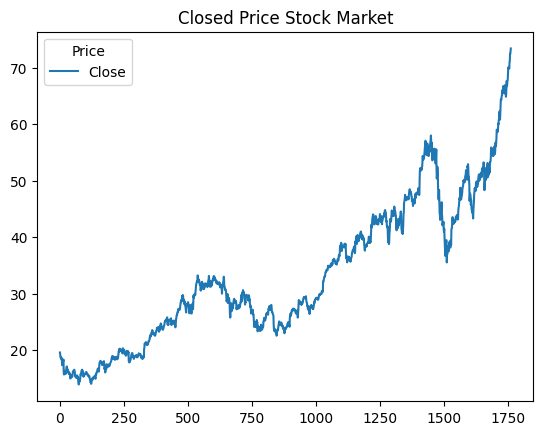

In [4]:
stock_data[['Close']].plot()
plt.title("Closed Price Stock Market")
plt.show()

## Outlier checking

In [5]:
# Create df from the existing stock dataset
df = stock_data.copy()

# Convert the Date column to datetime
df['Date'] = pd.to_datetime(df['Date'])

# Display the dataset
df


Price,Date,Adj Close,Close,High,Low,Open,Volume
0,2013-01-02,16.554535,19.608213,19.821428,19.343929,19.779285,560518000
1,2013-01-03,16.345579,19.360714,19.631071,19.321428,19.567142,352965200
2,2013-01-04,15.890275,18.821428,19.236786,18.779642,19.177500,594333600
3,2013-01-07,15.796807,18.710714,18.903570,18.400000,18.642857,484156400
4,2013-01-08,15.839315,18.761070,18.996071,18.616072,18.900356,458707200
...,...,...,...,...,...,...,...
1757,2019-12-24,68.350365,71.067497,71.222504,70.730003,71.172501,48478800
1758,2019-12-26,69.706467,72.477501,72.495003,71.175003,71.205002,93121200
1759,2019-12-27,69.680023,72.449997,73.492500,72.029999,72.779999,146266000
1760,2019-12-30,70.093552,72.879997,73.172501,71.305000,72.364998,144114400


In [6]:
# Specify the column to analyze for outliers
column_name = 'Open'

# Calculate the IQR (Interquartile Range)
Q1 = df[column_name].quantile(0.25)
Q3 = df[column_name].quantile(0.75)
IQR = Q3 - Q1

# Define the lower and upper bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify and count outliers
outliers = df[(df[column_name] < lower_bound) | (df[column_name] > upper_bound)]
num_outliers = len(outliers)

# Display the number of outliers
print(f'Number of outliers in {column_name}: {num_outliers}')


Number of outliers in Open: 3


In [7]:
# Specify the column to analyze for outliers
column_name = 'Close'

# Calculate the IQR (Interquartile Range)
Q1 = df[column_name].quantile(0.25)
Q3 = df[column_name].quantile(0.75)
IQR = Q3 - Q1

# Define the lower and upper bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify and count outliers
outliers = df[(df[column_name] < lower_bound) | (df[column_name] > upper_bound)]
num_outliers = len(outliers)

# Display the number of outliers
print(f'Number of outliers in {column_name}: {num_outliers}')


Number of outliers in Close: 4


/usr/local/lib/python3.13/dist-packages/seaborn/_base.py:1608: UserWarning:

Vertical orientation ignored with only `x` specified.

/tmp/ipykernel_444/2118448779.py:10: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




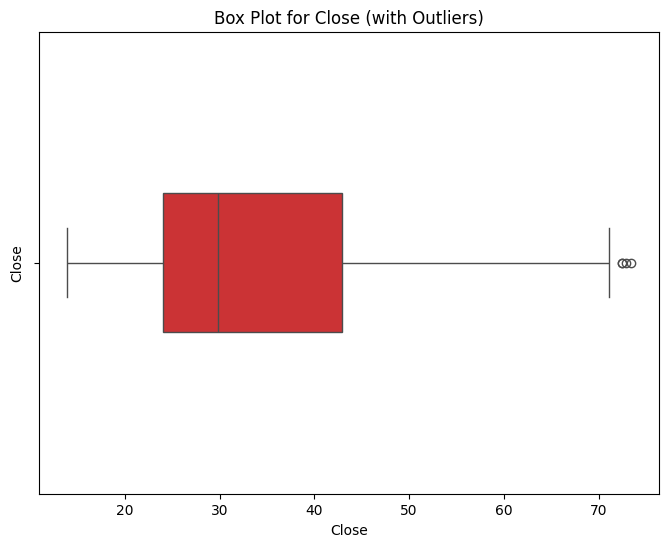

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns


# Specify the column to visualize outliers
column_name = 'Close'

# Create a box plot to visualize outliers
plt.figure(figsize=(8, 6))
sns.boxplot(x=df[column_name], orient='v', width=0.3, palette='Set1')
plt.title(f'Box Plot for {column_name} (with Outliers)')
plt.ylabel(column_name)
plt.show()


## Shared AAPL preprocessing (70% training / 15% testing / 15% final validation)


In [9]:
import torch
import numpy as np
import pandas as pd
import yfinance as yf
from google.colab import files

torch.manual_seed(42)
np.random.seed(42)

# Reuse the AAPL download from the first data cell.
# Exploration used only the training portion.
raw = raw_download.copy()

raw = raw.rename(
    columns={"Adj Close": "Adjusted Close"}
)

columns_to_normalize = [
    "Low", "Open", "Volume",
    "High", "Close", "Adjusted Close"
]

raw = raw[columns_to_normalize].sort_index().copy()
raw.index.name = "Date"

if raw.isna().any().any():
    raise ValueError("Missing AAPL stock values")

# Split chronologically: 70/15/15
train_size = int(len(raw) * 0.70)
test_size = int(len(raw) * 0.15)

train_raw = raw.iloc[:train_size].copy()
test_raw = raw.iloc[
    train_size:train_size + test_size
].copy()
val_raw = raw.iloc[
    train_size + test_size:
].copy()

# Export original stock data
train_raw.to_csv("AAPL_Training.csv")
test_raw.to_csv("AAPL_Testing.csv")
val_raw.to_csv("AAPL_Validation.csv")

print("Training:", len(train_raw))
print("Testing:", len(test_raw))
print("Validation:", len(val_raw))

# Express prices relative to the opening price or previous close.
# shift(1) uses only the previous trading day's close, even at split boundaries.
assert (raw["Open"] > 0).all() and (raw["Close"] > 0).all()
previous_close = raw["Close"].shift(1)
feature_columns = ["Low_vs_Open_pct", "Open_vs_Prev_Close_pct", "High_vs_Open_pct"]
target_column = "Close_vs_Open_pct"

def make_price_features(frame, prev_close):
    out = pd.DataFrame(index=frame.index)
    out["Low_vs_Open_pct"] = (frame["Low"] / frame["Open"] - 1) * 100
    out["Open_vs_Prev_Close_pct"] = (frame["Open"] / prev_close - 1) * 100
    out["High_vs_Open_pct"] = (frame["High"] / frame["Open"] - 1) * 100
    return out

def make_return_target(frame):
    return (frame["Close"] / frame["Open"] - 1) * 100

train_price = make_price_features(train_raw, previous_close.loc[train_raw.index])
test_price = make_price_features(test_raw, previous_close.loc[test_raw.index])
# No preceding observation exists for the first training day.
train_price.loc[train_price.index[0], "Open_vs_Prev_Close_pct"] = 0.0
train_return = make_return_target(train_raw)
test_return = make_return_target(test_raw)

# Fit separate input and target scalers ONLY on training observations.
price_mean = train_price.mean()
price_std = train_price.std(ddof=0).replace(0, 1)
return_mean = float(train_return.mean())
return_std = float(train_return.std(ddof=0)) or 1.0

def price_tensor(frame):
    normalized = (frame[feature_columns] - price_mean) / price_std
    if not np.isfinite(normalized.to_numpy()).all():
        raise ValueError("Invalid normalized price features")
    return torch.tensor(normalized.to_numpy(), dtype=torch.float32)

def target_tensor(returns):
    return torch.tensor((returns.to_numpy() - return_mean) / return_std, dtype=torch.float32)

def to_original_returns(values):
    return np.asarray(values).reshape(-1) * return_std + return_mean

def to_original_prices(values, opens):
    returns = to_original_returns(values)
    opens = np.asarray(opens).reshape(-1)
    if len(returns) != len(opens):
        raise ValueError("Return predictions and opening prices do not align")
    return opens * (1 + returns / 100)

train_features = price_tensor(train_price)
test_features = price_tensor(test_price)
train_target = target_tensor(train_return)
test_target = target_tensor(test_return)

print("Training price-feature shape:", train_features.shape)
print("Training return mean/std (%):", return_mean, return_std)
print("Raw split CSVs saved in the Colab Files panel.")
# The original raw CSVs are saved as before; no need to download them again.

Training: 1762
Testing: 377
Validation: 379
Training price-feature shape: torch.Size([1762, 3])
Training return mean/std (%): 0.02852230583082677 1.2026734795284968
Raw split CSVs saved in the Colab Files panel.


## LSTM

LSTM Epoch 10/100 | Train: 0.98610 | Test: 2.23605
LSTM Epoch 20/100 | Train: 0.94327 | Test: 2.15192
LSTM Epoch 30/100 | Train: 0.87143 | Test: 1.99885
LSTM Epoch 40/100 | Train: 0.74739 | Test: 1.73069
LSTM Epoch 50/100 | Train: 0.56045 | Test: 1.33691
LSTM Epoch 60/100 | Train: 0.34876 | Test: 0.91089
LSTM Epoch 70/100 | Train: 0.21687 | Test: 0.65796
LSTM Epoch 80/100 | Train: 0.20862 | Test: 0.62646
LSTM Epoch 90/100 | Train: 0.20113 | Test: 0.61703
LSTM Epoch 100/100 | Train: 0.19323 | Test: 0.61869


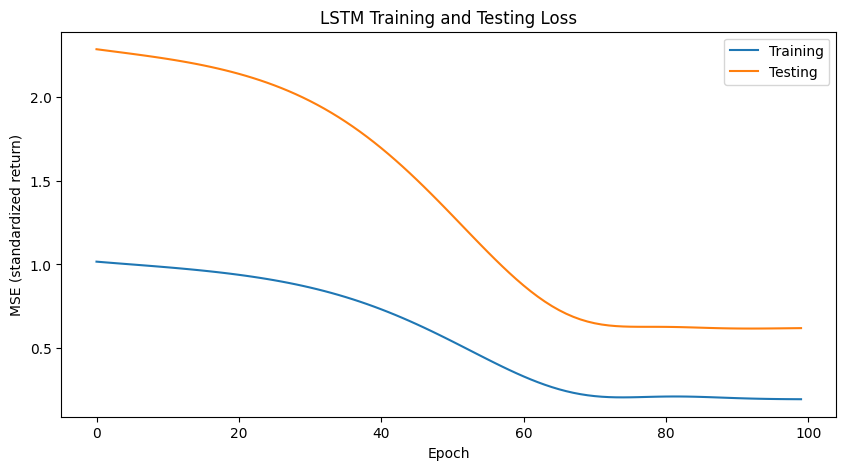

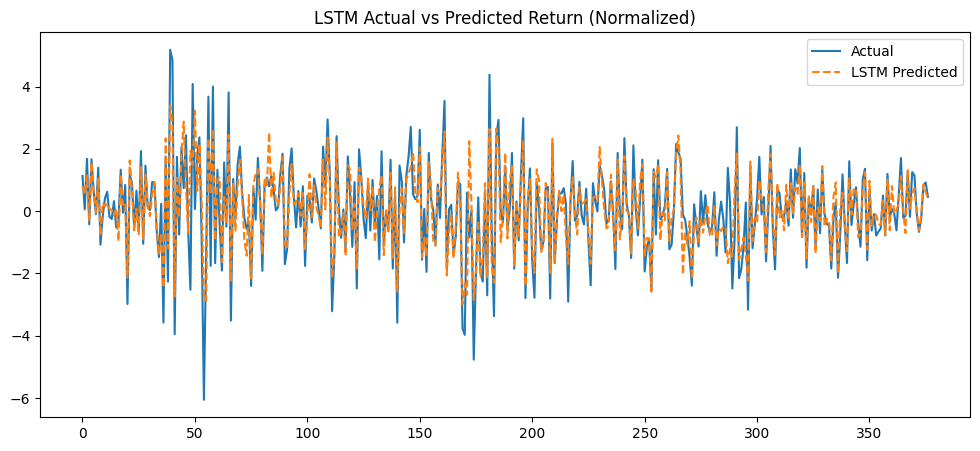

In [10]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)

class LSTMModel(nn.Module):
    def __init__(
        self, input_size, hidden_size,
        output_size, num_layers
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size,
            hidden_size,
            num_layers,
            batch_first=True
        )

        self.fc_output = nn.Linear(
            hidden_size, output_size
        )

    def forward(self, x):
        _, (hn, _) = self.lstm(x)
        return self.fc_output(hn[-1, :, :])


model_lstm = LSTMModel(3, 64, 1, 2)

criterion_lstm = nn.MSELoss()
optimizer_lstm = optim.Adam(
    model_lstm.parameters(),
    lr=0.001
)

train_losses_lstm = []
test_losses_lstm = []

for epoch in range(100):
    model_lstm.train()
    optimizer_lstm.zero_grad()

    outputs_lstm = model_lstm(
        train_features.unsqueeze(1)
    )

    loss_lstm = criterion_lstm(
        outputs_lstm,
        train_target.unsqueeze(1)
    )

    loss_lstm.backward()
    optimizer_lstm.step()

    train_losses_lstm.append(loss_lstm.item())

    model_lstm.eval()

    with torch.no_grad():
        pred = model_lstm(
            test_features.unsqueeze(1)
        )

        test_loss = criterion_lstm(
            pred,
            test_target.unsqueeze(1)
        )

    test_losses_lstm.append(test_loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"LSTM Epoch {epoch+1}/100 | "
            f"Train: {loss_lstm.item():.5f} | "
            f"Test: {test_loss.item():.5f}"
        )

# Final test predictions
model_lstm.eval()

with torch.no_grad():
    test_predictions_lstm = model_lstm(
        test_features.unsqueeze(1)
    ).squeeze(1).cpu().numpy()

# Training and testing loss graph
plt.figure(figsize=(10, 5))
plt.plot(train_losses_lstm, label="Training")
plt.plot(test_losses_lstm, label="Testing")
plt.xlabel("Epoch")
plt.ylabel("MSE (standardized return)")
plt.title("LSTM Training and Testing Loss")
plt.legend()
plt.show()

# Actual vs predicted
plt.figure(figsize=(12, 5))
plt.plot(
    test_target.numpy(),
    label="Actual"
)
plt.plot(
    test_predictions_lstm,
    "--",
    label="LSTM Predicted"
)
plt.title("LSTM Actual vs Predicted Return (Normalized)")
plt.legend()
plt.show()

In [11]:
from sklearn.metrics import r2_score
# R² here is for the return target, not for dollar closing prices.
r2 = r2_score(test_target.numpy(), test_predictions_lstm)
print(f"LSTM return R²: {r2:.4f}")

LSTM return R²: 0.7291


## Transformer

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:145: UserWarning:

enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)



Transformer Epoch 10/100 | Train: 0.33435 | Test: 0.73093
Transformer Epoch 20/100 | Train: 0.26685 | Test: 0.73615
Transformer Epoch 30/100 | Train: 0.23869 | Test: 0.69816
Transformer Epoch 40/100 | Train: 0.22371 | Test: 0.69120
Transformer Epoch 50/100 | Train: 0.20815 | Test: 0.76559
Transformer Epoch 60/100 | Train: 0.19770 | Test: 0.77348
Transformer Epoch 70/100 | Train: 0.19465 | Test: 0.80849
Transformer Epoch 80/100 | Train: 0.19092 | Test: 0.87446
Transformer Epoch 90/100 | Train: 0.18698 | Test: 0.88103
Transformer Epoch 100/100 | Train: 0.18700 | Test: 0.95141


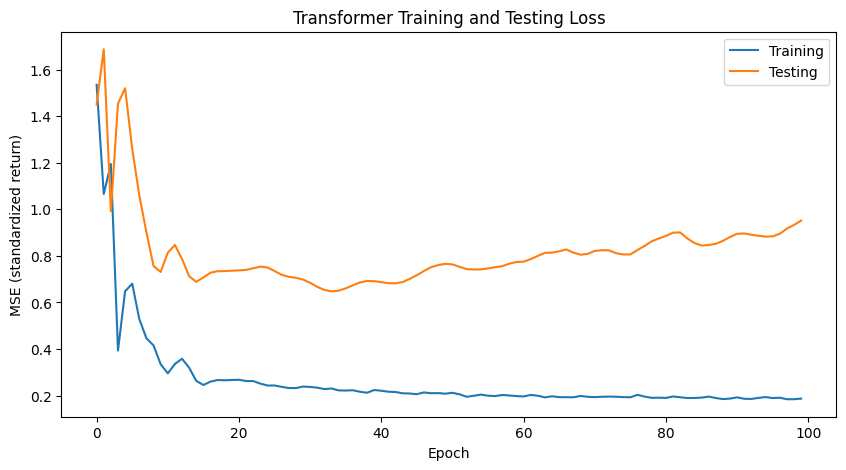

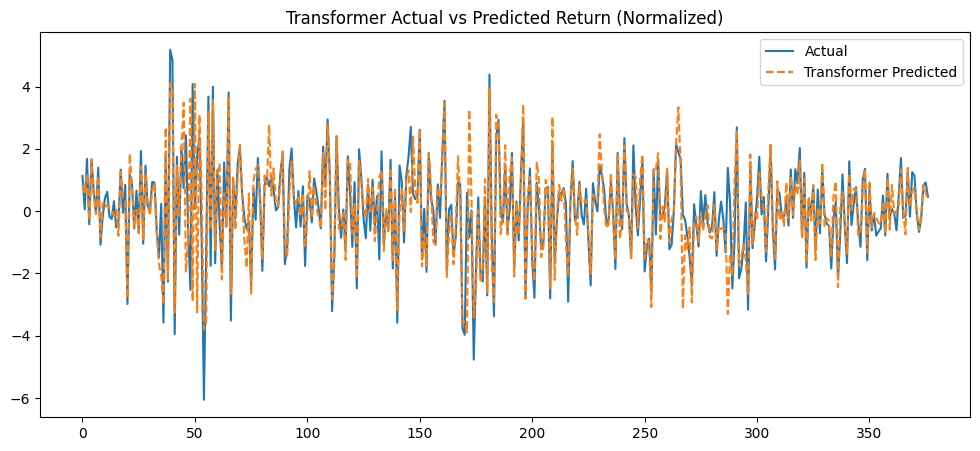

In [12]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

torch.manual_seed(42)

class TransformerModel(nn.Module):
    def __init__(
        self, input_size, hidden_size,
        output_size, num_layers,
        num_attention_heads
    ):
        super().__init__()

        self.embedding = nn.Linear(
            input_size, hidden_size
        )

        self.transformer = nn.Transformer(
            d_model=hidden_size,
            nhead=num_attention_heads,
            num_encoder_layers=num_layers,
            num_decoder_layers=num_layers
        )

        self.fc_output = nn.Linear(
            hidden_size, output_size
        )

    def forward(self, x):
        x = self.embedding(x)
        x = x.permute(1, 0, 2)
        x = self.transformer(x, x)
        x = x.permute(1, 0, 2)

        return self.fc_output(
            x[:, -1, :]
        )


transformer_model = TransformerModel(
    input_size=3,
    hidden_size=64,
    output_size=1,
    num_layers=2,
    num_attention_heads=4
)

criterion_transformer = nn.MSELoss()

optimizer_transformer = optim.Adam(
    transformer_model.parameters(),
    lr=0.001
)

train_losses = []
test_losses = []

for epoch in range(100):

    transformer_model.train()
    optimizer_transformer.zero_grad()

    outputs = transformer_model(
        train_features.unsqueeze(1)
    )

    loss = criterion_transformer(
        outputs,
        train_target.unsqueeze(1)
    )

    loss.backward()
    optimizer_transformer.step()

    train_losses.append(loss.item())

    transformer_model.eval()

    with torch.no_grad():
        pred = transformer_model(
            test_features.unsqueeze(1)
        )

        test_loss = criterion_transformer(
            pred,
            test_target.unsqueeze(1)
        )

    test_losses.append(test_loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Transformer Epoch {epoch+1}/100 | "
            f"Train: {loss.item():.5f} | "
            f"Test: {test_loss.item():.5f}"
        )

# Final test predictions
transformer_model.eval()

with torch.no_grad():
    test_predictions = transformer_model(
        test_features.unsqueeze(1)
    ).squeeze(1).cpu().numpy()

# Training and testing loss graph
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="Training")
plt.plot(test_losses, label="Testing")
plt.xlabel("Epoch")
plt.ylabel("MSE (standardized return)")
plt.title("Transformer Training and Testing Loss")
plt.legend()
plt.show()

# Actual vs predicted
plt.figure(figsize=(12, 5))
plt.plot(
    test_target.numpy(),
    label="Actual"
)
plt.plot(
    test_predictions,
    "--",
    label="Transformer Predicted"
)
plt.title("Transformer Actual vs Predicted Return (Normalized)")
plt.legend()
plt.show()

## GRU — price-only baseline


Epoch [10/100], Training Loss: 0.883107
Epoch [20/100], Training Loss: 0.726351
Epoch [30/100], Training Loss: 0.504270
Epoch [40/100], Training Loss: 0.276505
Epoch [50/100], Training Loss: 0.192065
Epoch [60/100], Training Loss: 0.203832
Epoch [70/100], Training Loss: 0.188047
Epoch [80/100], Training Loss: 0.187265
Epoch [90/100], Training Loss: 0.184684
Epoch [100/100], Training Loss: 0.183228

========== GRU TEST RESULTS ==========
MAE (Normalized):  0.5242
MSE (Normalized):  0.6017
RMSE (Normalized): 0.7757
R-squared:         0.7365

===== GRU ORIGINAL PRICE METRICS =====
MAE:  $0.6388
MSE:  0.8461
RMSE: $0.9198
MAPE: 0.6305%
Price R²: 0.9985


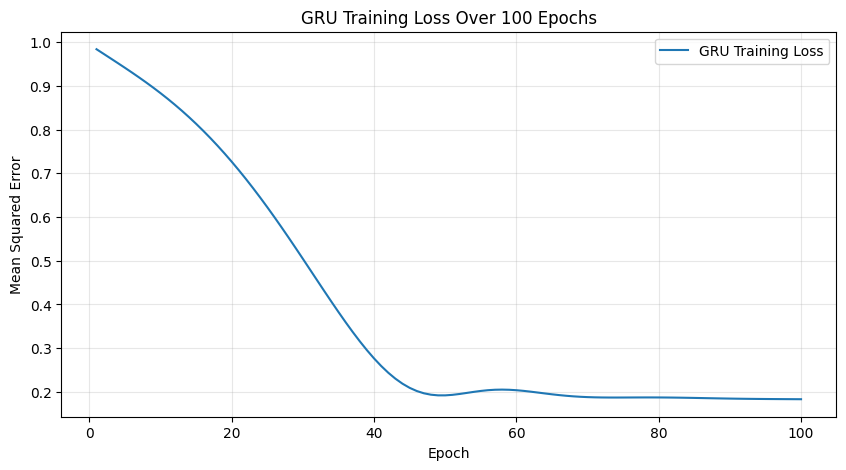

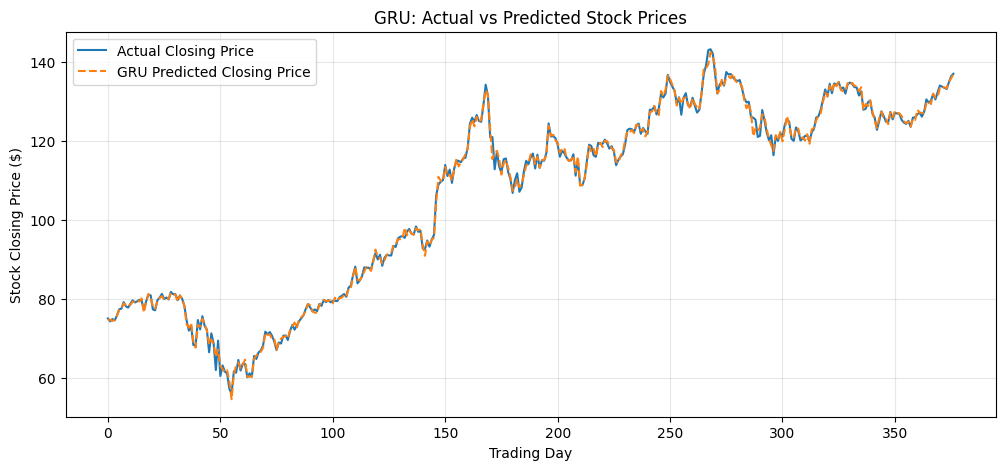


GRU training and evaluation complete!


In [13]:
# GRU MODEL - COMPARISON WITH LSTM AND TRANSFORMER


import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# DEFINE GRU MODEL

class GRUModel(nn.Module):
    def __init__(self, input_size, hidden_size,
                 num_layers, output_size):

        super(GRUModel, self).__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        gru_output, hidden = self.gru(x)
        return self.fc(gru_output[:, -1, :])


# DEFINE HYPERPARAMETERS

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Match LSTM and Transformer settings
input_size = 3
hidden_size = 64
num_layers = 2
output_size = 1

learning_rate = 0.001
num_epochs_gru = 100

# Create GRU model
model_gru = GRUModel(
    input_size=input_size,
    hidden_size=hidden_size,
    num_layers=num_layers,
    output_size=output_size
)

# Define loss function and optimizer
criterion_gru = nn.MSELoss()

optimizer_gru = optim.Adam(
    model_gru.parameters(),
    lr=learning_rate
)


# TRAIN THE GRU MODEL

gru_train_losses = []

for epoch in range(num_epochs_gru):

    model_gru.train()
    optimizer_gru.zero_grad()

    # Forward pass
    outputs = model_gru(train_features.unsqueeze(1))

    # Calculate training loss
    loss = criterion_gru(
        outputs,
        train_target.unsqueeze(1)
    )

    # Backpropagation
    loss.backward()
    optimizer_gru.step()

    gru_train_losses.append(loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{num_epochs_gru}], "
            f"Training Loss: {loss.item():.6f}"
        )


# EVALUATE ON TEST DATASET

model_gru.eval()

with torch.no_grad():
    gru_predictions = model_gru(
        test_features.unsqueeze(1)
    )

gru_predictions = (
    gru_predictions.squeeze(1).cpu().numpy()
)

actual = test_target.cpu().numpy()


# CALCULATE NORMALIZED METRICS

gru_mae = mean_absolute_error(actual, gru_predictions)
gru_mse = mean_squared_error(actual, gru_predictions)
gru_rmse = np.sqrt(gru_mse)
gru_r2 = r2_score(actual, gru_predictions)

print("\n========== GRU TEST RESULTS ==========")

print(f"MAE (Normalized):  {gru_mae:.4f}")
print(f"MSE (Normalized):  {gru_mse:.4f}")
print(f"RMSE (Normalized): {gru_rmse:.4f}")
print(f"R-squared:         {gru_r2:.4f}")


# CONVERT PREDICTED RETURNS BACK TO DOLLAR CLOSING PRICES
actual_prices = test_raw["Close"].to_numpy()
predicted_prices = to_original_prices(gru_predictions, test_raw["Open"])

# Calculate original-price metrics
gru_mae_original = mean_absolute_error(actual_prices, predicted_prices)
gru_mse_original = mean_squared_error(actual_prices, predicted_prices)
gru_rmse_original = np.sqrt(gru_mse_original)
gru_mape = np.mean(np.abs((actual_prices - predicted_prices) / actual_prices)) * 100
gru_price_r2 = r2_score(actual_prices, predicted_prices)

print("\n===== GRU ORIGINAL PRICE METRICS =====")
print(f"MAE:  ${gru_mae_original:.4f}")
print(f"MSE:  {gru_mse_original:.4f}")
print(f"RMSE: ${gru_rmse_original:.4f}")
print(f"MAPE: {gru_mape:.4f}%")
print(f"Price R²: {gru_price_r2:.4f}")

# VISUALIZE TRAINING LOSS

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, num_epochs_gru + 1),
    gru_train_losses,
    label="GRU Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("GRU Training Loss Over 100 Epochs")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# VISUALIZE ACTUAL VS PREDICTED STOCK PRICES

plt.figure(figsize=(12, 5))

plt.plot(
    actual_prices,
    label="Actual Closing Price"
)

plt.plot(
    predicted_prices,
    label="GRU Predicted Closing Price",
    linestyle="dashed"
)

plt.xlabel("Trading Day")
plt.ylabel("Stock Closing Price ($)")
plt.title("GRU: Actual vs Predicted Stock Prices")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("\nGRU training and evaluation complete!")

## News features — add after the standard GRU
Run the previous news-collection and FinBERT notebook first, then upload its scored CSV when prompted. No validation features are built in this cell. The trailing windows use calendar dates strictly before each target date. Three separate flags distinguish missing news from neutral sentiment at each window. The seven-day count is log-transformed; the four numeric news features are standardized using only training rows. Flags remain 0/1.

In [14]:
import os
import pandas as pd
import numpy as np
import torch
from google.colab import files

NEWS_FILE = "AAPL_FinBERT_Sentiment_2013_2022.csv"

if not os.path.exists(NEWS_FILE):
    uploaded = files.upload()
    if NEWS_FILE not in uploaded:
        raise FileNotFoundError(f"Please upload {NEWS_FILE}")

scored_news = pd.read_csv(NEWS_FILE)

required = {"date", "Sentiment"}
if not required.issubset(scored_news.columns):
    raise ValueError("News CSV must contain date and Sentiment columns.")

# Preserve the supplied publication calendar date
scored_news["date"] = pd.to_datetime(
    scored_news["date"].astype(str).str[:10], errors="coerce"
)
scored_news["Sentiment"] = pd.to_numeric(
    scored_news["Sentiment"], errors="coerce"
)

if scored_news[["date", "Sentiment"]].isna().any().any():
    raise ValueError("Invalid date or sentiment in the news CSV.")
if not scored_news["Sentiment"].between(-1, 1).all():
    raise ValueError("Expected FinBERT sentiment scores in [-1, 1].")

scored_news = scored_news.sort_values("date").reset_index(drop=True)
if "relevant_text" in scored_news.columns:
    scored_news = scored_news.drop_duplicates(["date", "relevant_text"])

if scored_news.empty:
    raise ValueError("No scored news records.")

def make_news_features(dates, articles):
    dates = pd.DatetimeIndex(dates).normalize()
    if dates.tz is not None:
        dates = dates.tz_localize(None)

    articles = articles.sort_values("date")
    news_dates = pd.DatetimeIndex(articles["date"])
    scores = articles["Sentiment"].to_numpy(dtype=np.float64)
    prefix = np.r_[0.0, np.cumsum(scores)]
    result = pd.DataFrame(index=dates)

    for window in (1, 3, 7):
        left = news_dates.searchsorted(
            dates - pd.Timedelta(days=window), side="left"
        )
        right = news_dates.searchsorted(dates, side="left")
        count = right - left
        total = prefix[right] - prefix[left]

        result[f"Sentiment_{window}D"] = np.divide(
            total, count, out=np.zeros(len(dates)), where=count > 0
        )
        result[f"Has_News_{window}D"] = (count > 0).astype(float)

        if window == 7:
            result["Log_News_Count_7D"] = np.log1p(count)

    return result

news_numeric = [
    "Sentiment_1D", "Sentiment_3D", "Sentiment_7D",
    "Log_News_Count_7D"
]
news_flags = ["Has_News_1D", "Has_News_3D", "Has_News_7D"]
news_columns = news_numeric + news_flags

# Restrict development news to dates before the last development target
development_news = scored_news[
    scored_news["date"] < pd.Timestamp(test_raw.index[-1]).normalize()
].copy()

train_news = make_news_features(train_raw.index, development_news)
test_news = make_news_features(test_raw.index, development_news)

# Fit the news scaler on training data only
news_mean = train_news[news_numeric].mean()
news_std = train_news[news_numeric].std(ddof=0).replace(0, 1)

def news_tensor(frame):
    features = frame[news_columns].copy()
    features[news_numeric] = (
        features[news_numeric] - news_mean
    ) / news_std
    return torch.tensor(features.to_numpy(), dtype=torch.float32)

# All rows stay in chronological order, including those without news
assert len(train_news) == len(train_features)
assert len(test_news) == len(test_features)

train_features_enhanced = torch.cat(
    [train_features, news_tensor(train_news)], dim=1
)
test_features_enhanced = torch.cat(
    [test_features, news_tensor(test_news)], dim=1
)

print("Price-only training shape:", tuple(train_features.shape))
print("Enhanced training shape:", tuple(train_features_enhanced.shape))
print("Enhanced testing shape:", tuple(test_features_enhanced.shape))
print("Training news coverage:")
print((train_news[news_flags].mean() * 100).round(2))
print("Testing news coverage:")
print((test_news[news_flags].mean() * 100).round(2))


Saving AAPL_FinBERT_Sentiment_2013_2022.csv to AAPL_FinBERT_Sentiment_2013_2022.csv
Price-only training shape: (1762, 3)
Enhanced training shape: (1762, 10)
Enhanced testing shape: (377, 10)
Training news coverage:
Has_News_1D    67.99
Has_News_3D    88.54
Has_News_7D    97.84
dtype: float64
Testing news coverage:
Has_News_1D     82.49
Has_News_3D     98.41
Has_News_7D    100.00
dtype: float64


## Sentiment-enhanced GRU — same training configuration
The enhanced model has 3 relative-price features + 7 news features = 10 inputs. Standard GRU remains the price-only control. All four predict the same standardized intraday return.

Enhanced GRU Epoch 10/100 | Loss: 0.919159
Enhanced GRU Epoch 20/100 | Loss: 0.785797
Enhanced GRU Epoch 30/100 | Loss: 0.571756
Enhanced GRU Epoch 40/100 | Loss: 0.312330
Enhanced GRU Epoch 50/100 | Loss: 0.193853
Enhanced GRU Epoch 60/100 | Loss: 0.206390
Enhanced GRU Epoch 70/100 | Loss: 0.186203
Enhanced GRU Epoch 80/100 | Loss: 0.186262
Enhanced GRU Epoch 90/100 | Loss: 0.182005
Enhanced GRU Epoch 100/100 | Loss: 0.180439


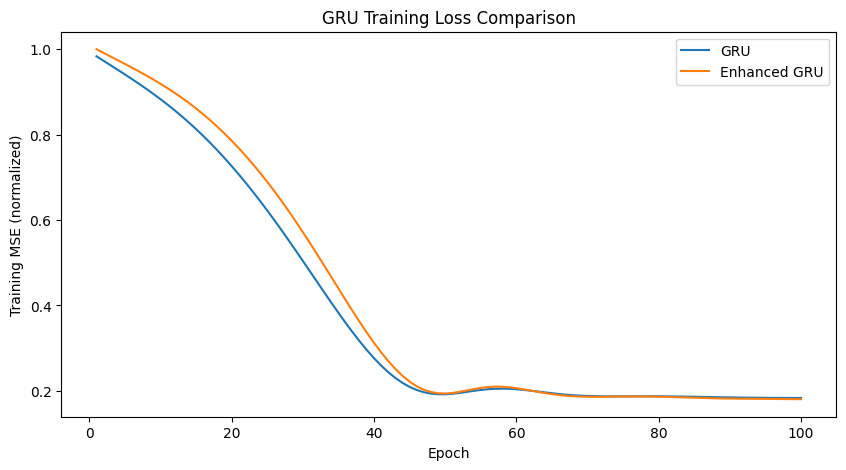

In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

model_gru_enhanced = GRUModel(
    input_size=train_features_enhanced.shape[1],
    hidden_size=64,
    num_layers=2,
    output_size=1
)

criterion_enhanced = nn.MSELoss()
optimizer_enhanced = optim.Adam(
    model_gru_enhanced.parameters(), lr=0.001
)

enhanced_train_losses = []

for epoch in range(100):
    model_gru_enhanced.train()
    optimizer_enhanced.zero_grad()

    outputs = model_gru_enhanced(
        train_features_enhanced.unsqueeze(1)
    )
    loss = criterion_enhanced(outputs, train_target.unsqueeze(1))
    loss.backward()
    optimizer_enhanced.step()
    enhanced_train_losses.append(loss.item())

    if (epoch + 1) % 10 == 0:
        print(f"Enhanced GRU Epoch {epoch+1}/100 | Loss: {loss.item():.6f}")

model_gru_enhanced.eval()
with torch.no_grad():
    enhanced_gru_predictions = model_gru_enhanced(
        test_features_enhanced.unsqueeze(1)
    ).squeeze(1).cpu().numpy()

plt.figure(figsize=(10, 5))
plt.plot(range(1, 101), gru_train_losses, label="GRU")
plt.plot(range(1, 101), enhanced_train_losses, label="Enhanced GRU")
plt.xlabel("Epoch")
plt.ylabel("Training MSE (normalized)")
plt.title("GRU Training Loss Comparison")
plt.legend()
plt.show()


## Compare all four models on the development test set


MODEL PERFORMANCE COMPARISON — DOLLAR PRICES
                   MAE ($)  MSE ($²)  RMSE ($)  MAPE (%)      R²
LSTM                0.6575    0.8594    0.9271    0.6513  0.9985
Transformer         0.6518    1.1893    1.0905    0.6523  0.9979
GRU                 0.6388    0.8461    0.9198    0.6305  0.9985
Enhanced GRU        0.6376    0.8534    0.9238    0.6284  0.9985
Opening price       1.4102    3.4057    1.8454    1.3768  0.9941
High-Low midpoint   0.8460    1.1656    1.0796    0.8352  0.9980

MODEL PERFORMANCE COMPARISON — INTRADAY RETURNS
                   MAE (pp)  RMSE (pp)      R²
LSTM                 0.6509     0.9460  0.7291
Transformer          0.6533     1.1731  0.5834
GRU                  0.6304     0.9329  0.7365
Enhanced GRU         0.6284     0.9314  0.7373
Opening price        1.3766     1.8197 -0.0025
High-Low midpoint    0.8355     1.0932  0.6382
Dollar RMSE reduction vs GRU: -0.43%
Return RMSE reduction vs GRU: 0.16%


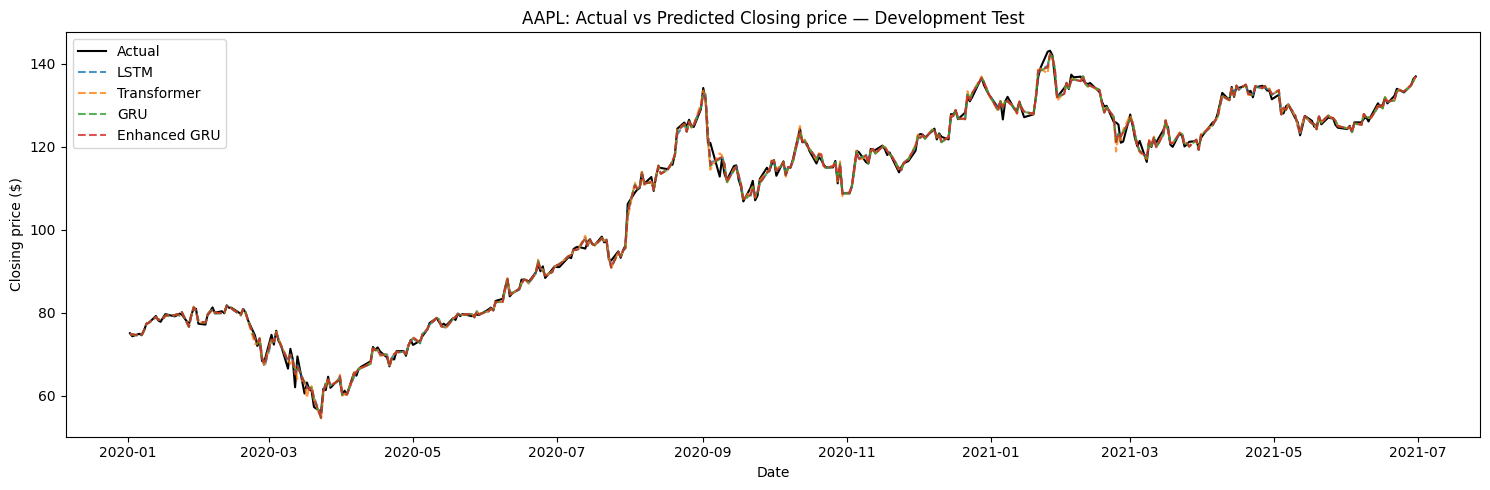

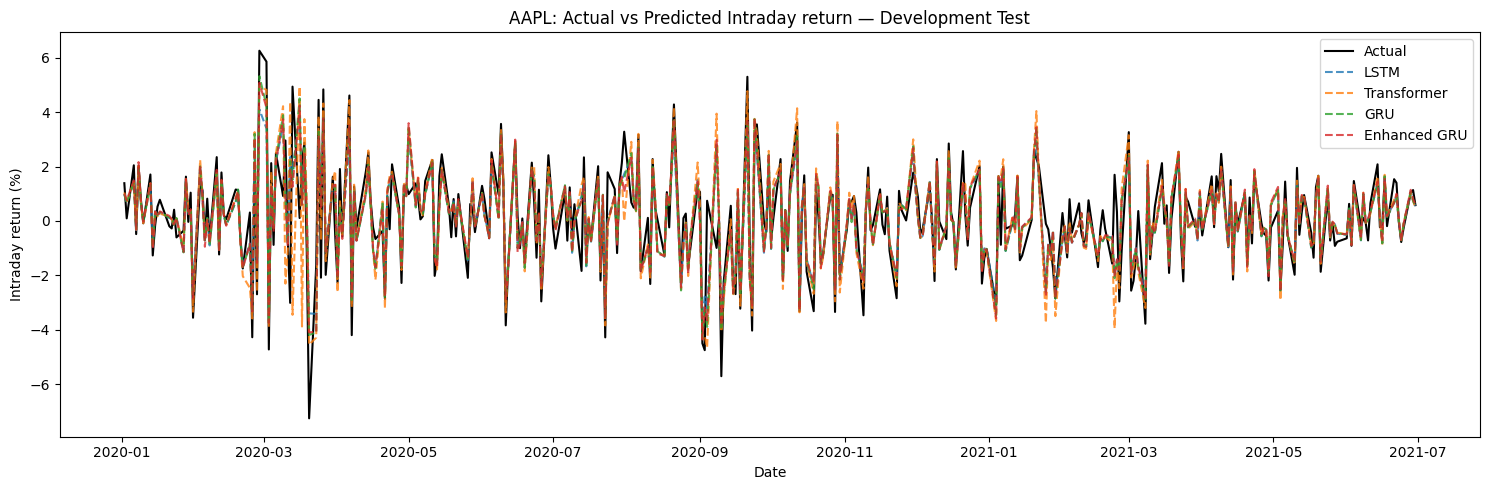

In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluate dollar closing prices and percentage-point intraday returns separately.
def price_metrics(actual, predicted):
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    mse = mean_squared_error(actual, predicted)
    return {"MAE ($)": mean_absolute_error(actual, predicted),
            "MSE ($²)": mse, "RMSE ($)": np.sqrt(mse),
            "MAPE (%)": np.mean(np.abs((actual - predicted) / actual)) * 100,
            "R²": r2_score(actual, predicted)}

def return_metrics(actual, predicted):
    mse = mean_squared_error(actual, predicted)
    return {"MAE (pp)": mean_absolute_error(actual, predicted),
            "RMSE (pp)": np.sqrt(mse), "R²": r2_score(actual, predicted)}

def compare_models(frame, normalized_predictions):
    opens = frame["Open"].to_numpy()
    actual = frame["Close"].to_numpy()
    actual_returns = make_return_target(frame).to_numpy()
    predicted_prices = {name: to_original_prices(values, opens)
                        for name, values in normalized_predictions.items()}
    predicted_returns = {name: to_original_returns(values)
                         for name, values in normalized_predictions.items()}
    # Simple reference models; midpoint uses same-day High and Low.
    for name, baseline in {"Opening price": opens,
                           "High-Low midpoint": ((frame["High"] + frame["Low"]) / 2).to_numpy()}.items():
        predicted_prices[name] = baseline
        predicted_returns[name] = (baseline / opens - 1) * 100
    prices = pd.DataFrame({name: price_metrics(actual, pred)
                           for name, pred in predicted_prices.items()}).T
    returns = pd.DataFrame({name: return_metrics(actual_returns, pred)
                            for name, pred in predicted_returns.items()}).T
    return prices, returns, predicted_prices, predicted_returns

assert np.allclose(to_original_prices(test_target.numpy(), test_raw["Open"]),
                   test_raw["Close"].to_numpy(), atol=1e-4)

comparison, return_comparison, test_price_predictions, test_return_predictions = compare_models(test_raw, {
    "LSTM": test_predictions_lstm,
    "Transformer": test_predictions,
    "GRU": gru_predictions,
    "Enhanced GRU": enhanced_gru_predictions
})
print("\nMODEL PERFORMANCE COMPARISON — DOLLAR PRICES")
print(comparison.round(4))
print("\nMODEL PERFORMANCE COMPARISON — INTRADAY RETURNS")
print(return_comparison.round(4))

# Report the effect of adding news to the GRU on both scales.
for label, table, col in [("Dollar", comparison, "RMSE ($)"),
                          ("Return", return_comparison, "RMSE (pp)")]:
    base = table.loc["GRU", col]
    enhanced = table.loc["Enhanced GRU", col]
    print(f"{label} RMSE reduction vs GRU: {(base - enhanced) / base * 100:.2f}%")

comparison.to_csv("AAPL_Return_Model_Price_Comparison.csv")
return_comparison.to_csv("AAPL_Return_Model_Return_Comparison.csv")

# Dollar-level fit can look strong simply because the opening price is known.
# Also plot intraday returns to show how well the models estimate actual movement.
for actual, predictions, ylabel, title in [
    (test_raw["Close"], test_price_predictions, "Closing price ($)", "Closing price"),
    (make_return_target(test_raw), test_return_predictions, "Intraday return (%)", "Intraday return")
]:
    plt.figure(figsize=(15, 5))
    plt.plot(test_raw.index, actual, color="black", label="Actual")
    for name, pred in predictions.items():
        if name not in ("Opening price", "High-Low midpoint"):
            plt.plot(test_raw.index, pred, linestyle="--", label=name, alpha=0.8)
    plt.xlabel("Date")
    plt.ylabel(ylabel)
    plt.title(f"AAPL: Actual vs Predicted {title} — Development Test")
    plt.legend()
    plt.tight_layout()
    plt.show()

## Optional final validation — do not enable during development
Only after all settings and model-selection decisions are frozen, change `RUN_FINAL_VALIDATION` to `True` and run this cell once. The results are separate from the development-test comparison. Do not tune models after viewing this table. If the validation data has previously influenced decisions, a new untouched holdout is needed for an independent final assessment.

In [17]:
RUN_FINAL_VALIDATION = False

if RUN_FINAL_VALIDATION:
    val_price = make_price_features(val_raw, previous_close.loc[val_raw.index])
    val_features = price_tensor(val_price)
    val_news = make_news_features(val_raw.index, scored_news)
    val_features_enhanced = torch.cat([val_features, news_tensor(val_news)], dim=1)

    validation_predictions = {}
    for name, fitted_model, inputs in [
        ("LSTM", model_lstm, val_features),
        ("Transformer", transformer_model, val_features),
        ("GRU", model_gru, val_features),
        ("Enhanced GRU", model_gru_enhanced, val_features_enhanced)
    ]:
        fitted_model.eval()
        with torch.no_grad():
            validation_predictions[name] = fitted_model(inputs.unsqueeze(1)).squeeze(1).cpu().numpy()

    validation_comparison, validation_return_comparison, _, _ = compare_models(val_raw, validation_predictions)
    print("FINAL HELD-OUT VALIDATION — DOLLAR PRICES")
    print(validation_comparison.round(4))
    print("FINAL HELD-OUT VALIDATION — INTRADAY RETURNS")
    print(validation_return_comparison.round(4))
    validation_comparison.to_csv("AAPL_Return_Final_Validation_Prices.csv")
    validation_return_comparison.to_csv("AAPL_Return_Final_Validation_Returns.csv")
else:
    print("Final validation remains reserved.")

Final validation remains reserved.
